# NFL rest advantage: a causal estimate with Double Machine Learning

## Problem
Do teams with more days of rest than their opponent really score more? Raw comparisons mix the effect of rest with who tends to have more rest (for example, strong teams after a Thursday win). We estimate the effect of the rest difference on the game margin after adjusting for team strength, and we are explicit about what such an estimate can and cannot say.

## Data
nflverse regular-season games 2015 to 2026 (`games.csv`: scores, rest days for each team, closing spread, roof, divisional game) and team-week EPA features built in `moneyball.py` (pre-game offensive and defensive efficiency of both teams, shifted so only past information is used).

## Method
Partially linear model $Y=\theta D+g(X)+\varepsilon$, $D=m(X)+v$ with $Y$ the home margin, $D$ the home minus away rest days and $X$ the pre-game strength and context features. DML estimator with cross-fitting (folds grouped by season so a season is never split between fitting and residualising): $\hat\theta=\sum\hat v_i\hat u_i/\sum\hat v_i^2$, with $\hat u=Y-\hat g(X)$ and $\hat v=D-\hat m(X)$ and a heteroskedasticity-robust standard error. Checks: naive and adjusted OLS for comparison, a placebo outcome that rest cannot cause (pre-game strength difference) and a specification that also controls for the market spread.

2882 games | 2015 to 2026
{'count': 2882.0, 'mean': -0.06, 'std': 2.47, 'min': -8.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 8.0}
Share of games with a rest difference != 0: 0.355


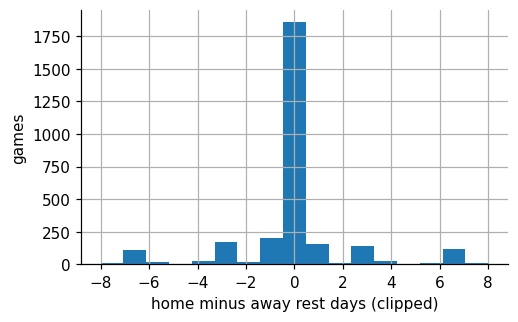

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import moneyball as M
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
import statsmodels.api as sm
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
g = M.load('https://raw.githubusercontent.com/nflverse/nfldata/master/data/games.csv','games.csv')
g = g[(g.game_type=='REG') & g.season.between(2015, 2026)].dropna(subset=['result','spread_line','home_rest','away_rest'])
r = M.add_rolling(M.team_weeks(2015, 2026))
h = r.add_prefix('h_').rename(columns={'h_season':'season','h_week':'week','h_team':'home_team'})
a = r.add_prefix('a_').rename(columns={'a_season':'season','a_week':'week','a_team':'away_team'})
d = g.merge(h, on=['season','week','home_team']).merge(a, on=['season','week','away_team']).dropna(subset=['h_off','h_dfn','a_off','a_dfn']).reset_index(drop=True)
d['rest_diff'] = d.home_rest - d.away_rest
d['roof_dome'] = d.roof.isin(['dome','closed']).astype(int); d['div'] = d.div_game.astype(int)
d['strength_diff'] = (d.h_off - d.h_dfn) - (d.a_off - d.a_dfn)
print(len(d), 'games |', d.season.min(), 'to', d.season.max())
print(d.rest_diff.describe().round(2).to_dict())
print('Share of games with a rest difference != 0:', round((d.rest_diff!=0).mean(), 3))
plt.figure(figsize=(5,3)); d.rest_diff.clip(-8,8).hist(bins=17); plt.xlabel('home minus away rest days (clipped)'); plt.ylabel('games'); plt.show()

In [2]:
# Raw look: margin by rest difference
bins = pd.cut(d.rest_diff, [-20,-3,-1,0,1,3,20], labels=['<=-3','-2,-1','0','1','2,3','>=4'])
print(d.groupby(bins, observed=True).agg(games=('result','size'), mean_margin=('result','mean'), mean_strength_diff=('strength_diff','mean')).round(2))

           games  mean_margin  mean_strength_diff
rest_diff                                        
<=-3         338         0.15                0.01
-2,-1        215         3.04               -0.00
0           1859         1.35               -0.01
1            156         1.99               -0.01
2,3          155         2.90                0.03
>=4          159         3.94                0.03


In [3]:
X_cols = ['h_off','h_dfn','a_off','a_dfn','roof_dome','div','week']
def dml(y, D, X, groups, model='gb', n_splits=5, seed=0):
    mk = (lambda: GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=.05, subsample=.8, random_state=seed)) if model=='gb' else (lambda: LinearRegression())
    u = np.zeros(len(y)); v = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits).split(X, y, groups):
        u[te] = y[te] - mk().fit(X[tr], y[tr]).predict(X[te])
        v[te] = D[te] - mk().fit(X[tr], D[tr]).predict(X[te])
    th = (v*u).sum()/(v*v).sum(); eps = u - th*v
    se = np.sqrt(((v*eps)**2).sum())/(v*v).sum()
    return th, se, 1 - u.var()/y.var(), 1 - v.var()/D.var()
y = d.result.values.astype(float); D = d.rest_diff.values.astype(float); grp = d.season.values
res = []
ols = sm.OLS(y, sm.add_constant(D)).fit(); res.append(('Naive OLS (no controls)', ols.params[1], ols.bse[1], np.nan, np.nan))
Xm = sm.add_constant(np.column_stack([D, d[X_cols].values])); o2 = sm.OLS(y, Xm).fit(cov_type='HC1'); res.append(('OLS with controls', o2.params[1], o2.bse[1], np.nan, np.nan))
for name, mdl, cols in [('DML linear nuisances', 'lin', X_cols), ('DML boosting nuisances', 'gb', X_cols), ('DML boosting + market spread', 'gb', X_cols+['spread_line'])]:
    th, se, r2y, r2d = dml(y, D, d[cols].values.astype(float), grp, mdl); res.append((name, th, se, r2y, r2d))
out = pd.DataFrame(res, columns=['method','theta (points per rest day)','se','R2 outcome','R2 treatment'])
out['ci_low'] = out.iloc[:,1]-1.96*out.se; out['ci_high'] = out.iloc[:,1]+1.96*out.se
print(out.round(3).to_string(index=False))

                      method  theta (points per rest day)    se  R2 outcome  R2 treatment  ci_low  ci_high
     Naive OLS (no controls)                        0.256 0.107         NaN           NaN   0.046    0.466
           OLS with controls                        0.227 0.091         NaN           NaN   0.049    0.405
        DML linear nuisances                        0.208 0.091       0.111        -0.004   0.031    0.386
      DML boosting nuisances                        0.205 0.092       0.087        -0.029   0.024    0.386
DML boosting + market spread                        0.031 0.089       0.169        -0.014  -0.143    0.205


In [4]:
# Placebo: rest cannot cause the pre-game strength difference, so the estimated effect should be ~0
th, se, _, _ = dml(d.strength_diff.values.astype(float), D, d[['roof_dome','div','week']].values.astype(float), grp, 'gb')
print(f'Placebo outcome (pre-game strength difference): theta = {th:.4f} (se {se:.4f}); z = {th/se:.2f}')
th2, se2, _, _ = dml(y, D, d[X_cols].values.astype(float), np.random.RandomState(1).permutation(grp), 'gb')
print(f'Sensitivity: DML boosting with different fold assignment: theta = {th2:.3f} (se {se2:.3f})')

Placebo outcome (pre-game strength difference): theta = 0.0011 (se 0.0014); z = 0.73


Sensitivity: DML boosting with different fold assignment: theta = 0.229 (se 0.093)


Games with a rest difference (n=1023): theta = 0.243 (se 0.093)
Games with >=3 days difference: 639 | mean margin (home more rest): 3.38 | (home less rest): 0.15


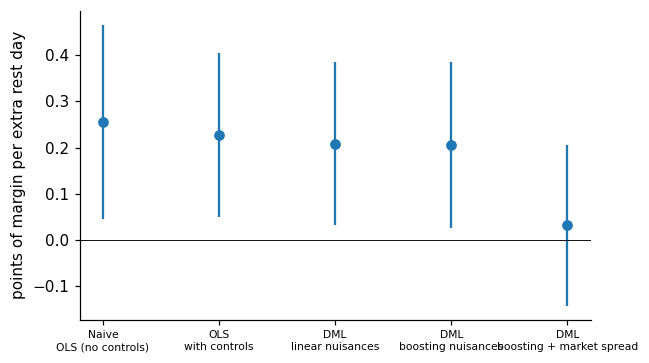

In [5]:
# Overlap and heterogeneity: effect only where rest actually differs, and by extreme short-week games
mask = d.rest_diff.abs() >= 1
th, se, _, _ = dml(y[mask], D[mask], d.loc[mask, X_cols].values.astype(float), grp[mask], 'gb')
print(f'Games with a rest difference (n={mask.sum()}): theta = {th:.3f} (se {se:.3f})')
big = d.rest_diff.abs() >= 3
print('Games with >=3 days difference:', int(big.sum()), '| mean margin (home more rest):', round(d[big & (d.rest_diff>0)].result.mean(),2), '| (home less rest):', round(d[big & (d.rest_diff<0)].result.mean(),2))
fig, ax = plt.subplots(figsize=(6,3.4)); ax.errorbar(range(len(out)), out.iloc[:,1], yerr=1.96*out.se, fmt='o'); ax.axhline(0, c='k', lw=.6)
ax.set_xticks(range(len(out))); ax.set_xticklabels([m.replace(' ','\n',1) for m in out.method], fontsize=7); ax.set_ylabel('points of margin per extra rest day'); plt.tight_layout(); plt.show()

## Results
See the outputs above: the distribution of the rest difference, the raw margin by rest bin, the table of estimates (naive and adjusted OLS and three DML specifications), the placebo and sensitivity checks and the estimate restricted to games with a real rest difference.

## Conclusions
1. **An extra rest day is worth about 0.2 points of margin.** Over 2,882 games (2015 to 2026), DML with boosting nuisance models estimates 0.205 points per extra day of rest advantage (95% CI 0.024 to 0.386); linear nuisances give 0.208 and a different fold assignment 0.229. Games with a real rest difference give 0.243. A team with a 3 to 4 day advantage is therefore worth roughly 0.6 to 0.9 points, which is small compared with the typical margin standard deviation of about 13 points.
2. **Adjustment barely changes the answer, because rest is almost random with respect to team strength.** The naive estimate (0.256) and the adjusted estimates (0.205 to 0.227) are close, and the models cannot predict the rest difference from team strength (out-of-fold R-squared of the treatment is about 0). That is what a schedule-driven treatment looks like, which makes the causal reading more credible than in most observational settings.
3. **The placebo check passes.** Rest cannot cause pre-game strength, and the estimated "effect" on the strength difference is 0.001 (standard error 0.001, z = 0.73), consistent with no spurious relationship between rest and team quality.
4. **The betting market already prices it.** Controlling for the closing spread shrinks the estimate to 0.031 (CI -0.143 to 0.205), so the information in rest days is already incorporated in the line. This agrees with the NFL Moneyball result that public data does not beat the market: the rest effect is real but not exploitable.
5. **Limits.** The raw means by rest bin are noisy (for example the 1 to 2 day deficit bin has a 3.0 margin, with only 215 games), the confidence interval for the main estimate is wide relative to its size, travel, injuries and weather are not controlled, and DML only adjusts for observed variables.

**Takeaway for the interview:** DML is valuable when you can argue the treatment is close to random (here, the schedule); the placebo and the market-spread control are the checks that turn a regression into a credible causal statement, and the honest conclusion is a small effect that the market already knows.